In [66]:
from rdkit import Chem
import pickle
import os
import json
import joblib
import numpy as np
import xgboost
import sys
sys.path.append('molecule-web-app/backend')
from ml_helper import make_fingerprint
from matplotlib import pyplot as plt
from cycler import cycler


In [67]:
from matplotlib.colors import ListedColormap
import numpy as np

# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

In [68]:
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [69]:
reactions_dir = "reactions"
reaction_id = 5
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 6 pickle files to RDKit Mol objects.


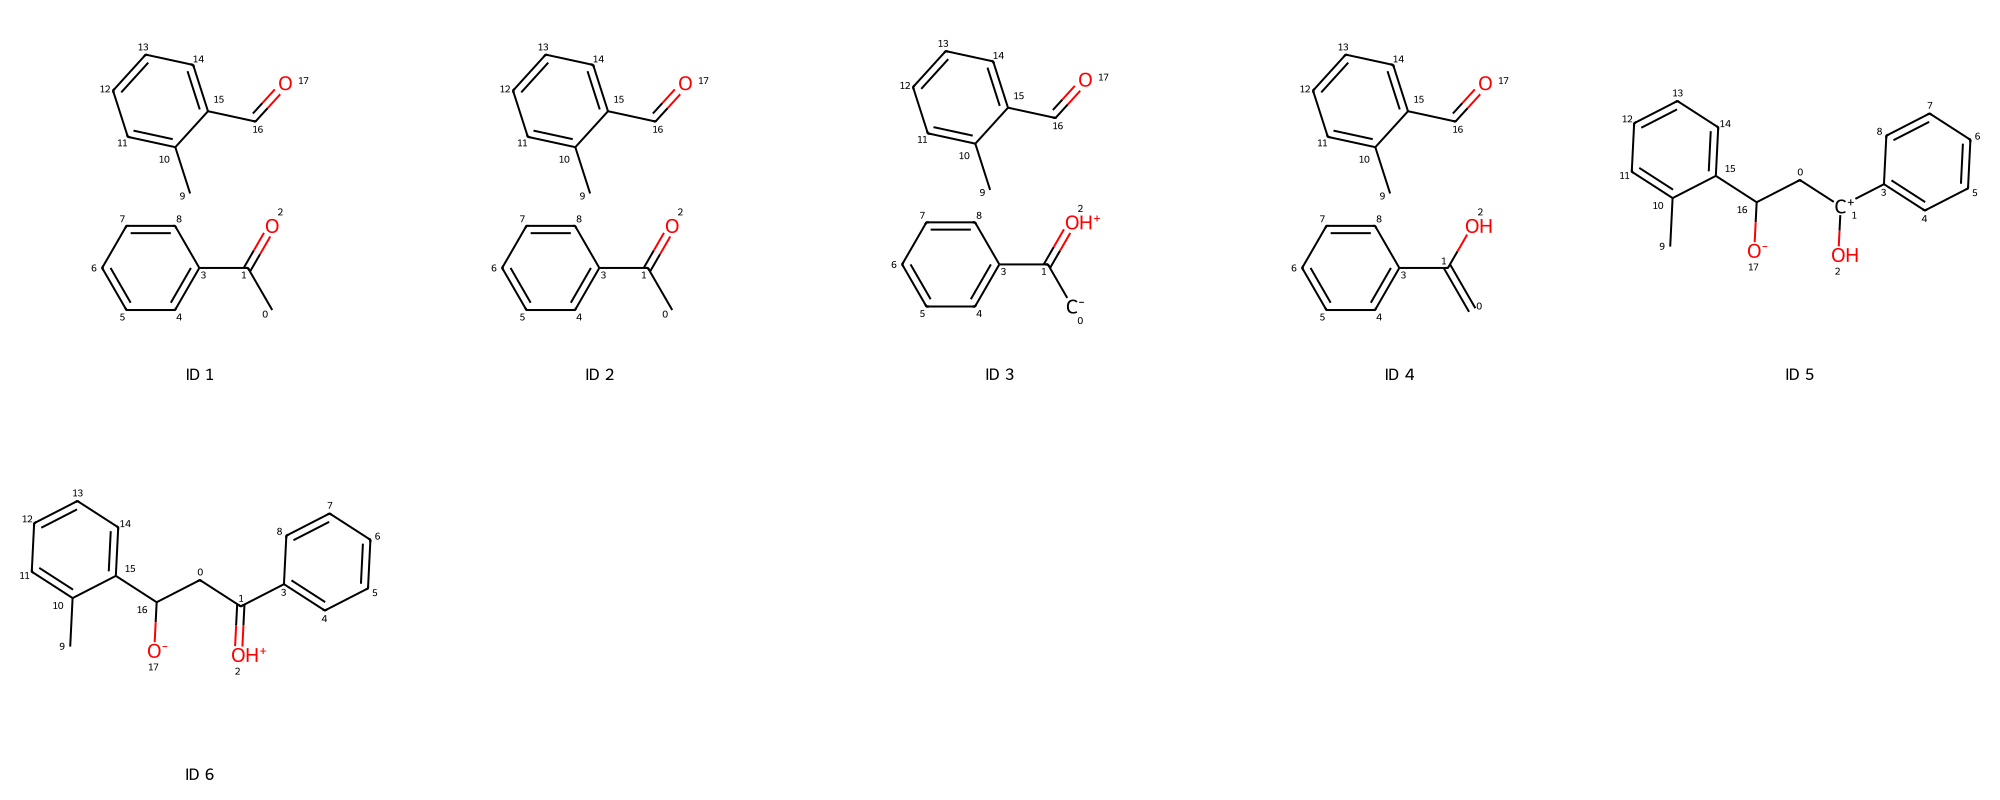

In [70]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(400, 400), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

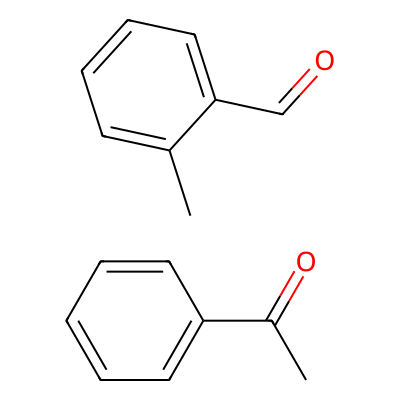

In [71]:
mol_problem = mol_objects[1]
mol_problem
Chem.SanitizeMol(mol_problem)
Chem.Draw.IPythonConsole.molSize = (400,400)
mol_problem

In [72]:
training_id = 16
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

Converted 2 pickle files to RDKit Mol objects.
{'choices': {'0': {'mechanism': [1, 2, 0, None, 1], 'probable': 1}}}


In [73]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20250616"

with open('bitvector_origins.txt', 'w') as origin_file:
    pass #

# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []

for subdir in subdirs:
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    for id, info in choices.items():
        # bitvector for the mechanism
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
            bitvectors.append(sum_finger_print)
            outcomes.append(info['probable'])
            # Track the origin of each bitvector
            with open("bitvector_origins.txt", "a") as origin_file:
                origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")



In [74]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score

In [56]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
#joblib.dump(clf, 'model.pkl')

Accuracy: 0.9293628808864266
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.98      0.96      1278
           1       0.79      0.52      0.63       166

    accuracy                           0.93      1444
   macro avg       0.87      0.75      0.80      1444
weighted avg       0.92      0.93      0.92      1444



In [75]:
from xgboost import XGBClassifier

In [65]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

ratio = len(outcomes)/sum(outcomes)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 20, eval_metric='logloss')
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'models/v12/xg_model.pkl')
clf.save_model('models/v12/xg_model_high.json')

8.444444444444445
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      1258
           1       0.66      0.80      0.72       186

    accuracy                           0.92      1444
   macro avg       0.81      0.87      0.84      1444
weighted avg       0.93      0.92      0.92      1444



In [25]:
precisions =[]
precisions_sd = []
recalls = []
recalls_sd =[]
f1_scores = []
f1_scores_sd = []
from sklearn.metrics import f1_score
pos_weight = 15

iter = 10
for i in range(pos_weight):
    precision = []
    recall = []
    f1 = []
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        # Get recall for positive class only (label=1)
        recall.append(recall_score(y_test, y_pred, pos_label=1))
        precision.append(precision_score(y_test, y_pred, pos_label=1))
        f1.append(f1_score(y_test, y_pred, pos_label=1))
    precisions.append(np.mean(np.array(precision)))
    precisions_sd.append(np.std(np.array(precision)))
    recalls.append(np.mean(np.array(recall)))
    recalls_sd.append(np.std(np.array(recall)))
    f1_scores.append(np.mean(np.array(f1)))
    f1_scores_sd.append(np.std(np.array(f1)))



In [23]:
print(f1_scores_sd)

[np.float64(0.048674321728475835), np.float64(0.02855178238536098), np.float64(0.02941580328073533), np.float64(0.03670433443735363), np.float64(0.03524226180508704), np.float64(0.03106724645176485), np.float64(0.0342592664362103), np.float64(0.02363628565787127), np.float64(0.03595755206197308), np.float64(0.04478477815356536), np.float64(0.03074396673467343), np.float64(0.024321682729249908), np.float64(0.03243233341493752), np.float64(0.03392116020836987), np.float64(0.05165047721339581)]


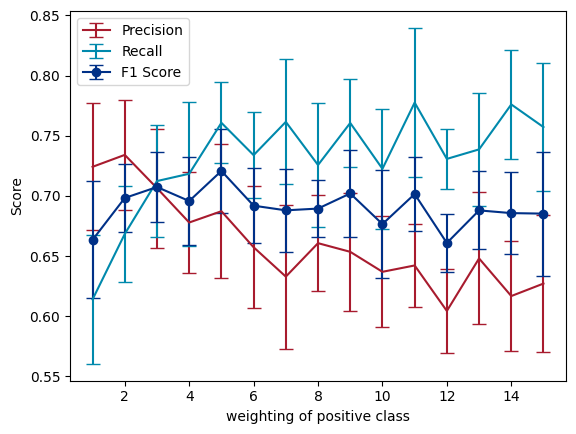

In [24]:
from matplotlib import pyplot as plt
from cycler import cycler
plt.errorbar(range(1, pos_weight+1), precisions, yerr=precisions_sd, label='Precision', capsize=5)
plt.errorbar(range(1, pos_weight+1), recalls, yerr =recalls_sd, label='Recall', capsize=5)
plt.errorbar(range(1, pos_weight+1), f1_scores, yerr=f1_scores_sd, label='F1 Score', fmt='-o', capsize=5)
plt.rc('axes', prop_cycle=cycler('color', custom_c))
plt.xlabel('weighting of positive class')
plt.ylabel('Score')
plt.legend()
#plt.show()
plt.savefig('pos_weighting.png', dpi=300)

In [81]:
import seaborn as sns


plt.figure(figsize=(10, 6))
sns.heatmap(bitvectors, cmap="Greys", cbar=False)
plt.xlabel("Bit Index")
plt.ylabel("Sample Index")
plt.title("Bitvector Activity")
plt.show()

NameError: name 'plt' is not defined

In [15]:
np.sum(np.array(bitvectors), axis=0)

array([  20,  395,    0,  341,  318,  203,    6,   15,    0,    0,  134,
       1158,    6,  493,  585,  166,   54,   12,  835,  451,    0,   21,
        640,  124,  283,    6,    0,    0,    0,    0,    2,   96,   95,
         31,    0,  284,   66,   35,  754,  406,  308,  124,  139,    0,
         29, 1183,   86,  279,  648,  184,  187,   41,  816,  441,    0,
         19, 1083,   51,   54,    0,   37,   19,    0,    0,    1,   12,
         12,   10,    0,  344,   99,   67,  982,  294,  221,  412,   57,
          0,   36,  514,    0,    0,  214,  451,    4,    0,  314,  160,
         55,   26,    7])

In [82]:
np.array(bitvectors).shape

(1506, 91)

NameError: name 'plt' is not defined

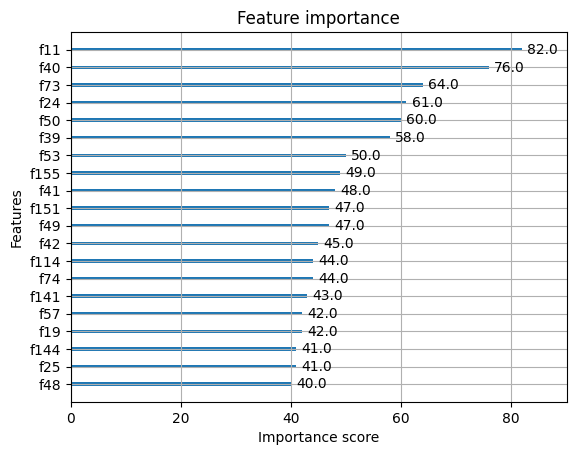

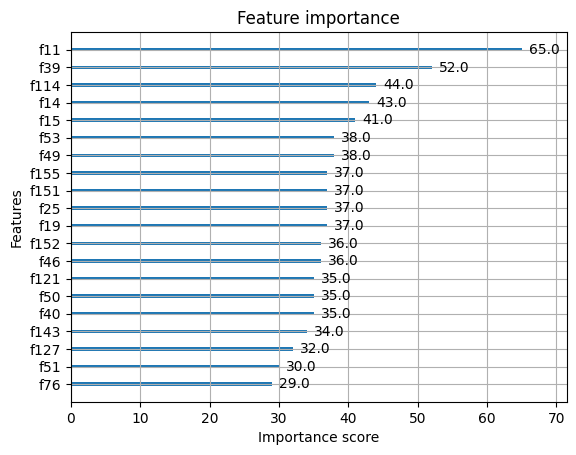

In [35]:
clf1 = joblib.load('models/v12/xg_model.pkl')
clf2 = joblib.load('models/v11/xg_model.pkl')
xgboost.plot_importance(clf1, max_num_features=20)
xgboost.plot_importance(clf2, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [49]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9028571428571428
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.98      0.94       442
           1       0.81      0.51      0.62        83

    accuracy                           0.90       525
   macro avg       0.86      0.74      0.78       525
weighted avg       0.90      0.90      0.89       525



In [41]:
%run ml_tools/get_feature.py 10

Feature at index 10: Atom 1 - Charge Bit


Can we learn chemical reactions from the reaction space

In [23]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances


mask = np.array(outcomes) == 1
X = np.array(bitvectors)[mask]


# Use Jaccard distance
distances = pairwise_distances(np.array(bitvectors), metric='jaccard')

# Fit kNN using precomputed distances
#knn = NearestNeighbors(n_neighbors=2, metric='precomputed')
#knn.fit(distances)

# Find nearest neighbors of a specific vector
#dists, indices = knn.kneighbors([distances[0]])
#print("Nearest neighbors of first bitstring:", indices)

/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [39]:
from sklearn.cluster import DBSCAN

# Compute Jaccard distance matrix
dist = pairwise_distances(X, metric='jaccard')

# Cluster using DBSCAN
clustering = DBSCAN(metric='precomputed', eps=0.2, min_samples=3)
labels = clustering.fit_predict(dist)

print("Cluster labels:", labels)

Cluster labels: [ 0  0  1  0  1 -1 -1 -1  2 -1 -1 -1  3  3 -1 -1 -1  1  4  4  4  4  1  4
  1 -1 -1 -1 -1 -1  3 -1 -1 -1 -1 -1  5 -1  6 -1  5  7  5  8  9 10 11  7
  5 -1 -1  7 -1  5  7 -1 -1  5  7  6  6 -1 -1  5  5 -1 -1 12  5 -1 -1 -1
 -1 12  6  5 13  8  5 10 11 -1 -1 -1 -1  5  9 -1  5 -1  9 10 -1  5 13 -1
  9  7  5 -1  7 -1 -1 -1 -1 -1 -1  5 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 13 -1 -1  5 -1 -1  7 -1 -1  3  5  9  9  9  7  7  7  7  7
  7  7  7  7  7  7  8 11 -1  3  3 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1 -1 -1
 -1 -1  2 -1  5 -1 -1 14 -1 -1 -1 14 -1 -1 -1 12 14 -1 -1 -1 -1 -1  6 -1
  5 -1 -1 -1 -1  5  9  7 -1 -1 -1 -1 -1 -1 -1  5 -1  9 -1  5  9 -1]


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [40]:
len(labels)

214

In [41]:
len(bitvectors)

1506

In [42]:
from collections import defaultdict

clusters = defaultdict(list)
for idx, label in enumerate(labels):
    clusters[label].append(idx)

for cluster_id, members in clusters.items():
    if cluster_id == -1:
        print(f"Noise points: {members}")
    else:
        print(f"Cluster {cluster_id}: {members}")

Cluster 0: [0, 1, 3]
Cluster 1: [2, 4, 17, 22, 24]
Noise points: [5, 6, 7, 9, 10, 11, 14, 15, 16, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 37, 39, 49, 50, 52, 55, 56, 61, 62, 65, 66, 69, 70, 71, 72, 81, 82, 83, 84, 87, 89, 92, 95, 99, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 129, 130, 132, 133, 152, 155, 156, 157, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 171, 173, 174, 176, 177, 178, 180, 181, 182, 185, 186, 187, 188, 189, 191, 193, 194, 195, 196, 200, 201, 202, 203, 204, 205, 206, 208, 210, 213]
Cluster 2: [8, 163, 170]
Cluster 3: [12, 13, 30, 134, 153, 154]
Cluster 4: [18, 19, 20, 21, 23]
Cluster 5: [36, 40, 42, 48, 53, 57, 63, 64, 68, 75, 78, 85, 88, 93, 98, 107, 128, 135, 172, 192, 197, 207, 211]
Cluster 6: [38, 59, 60, 74, 190]
Cluster 7: [41, 47, 51, 54, 58, 97, 100, 131, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 199]
Cluster 8: [43, 77, 150]
Cluster 9: [44, 86, 90, 96, 1

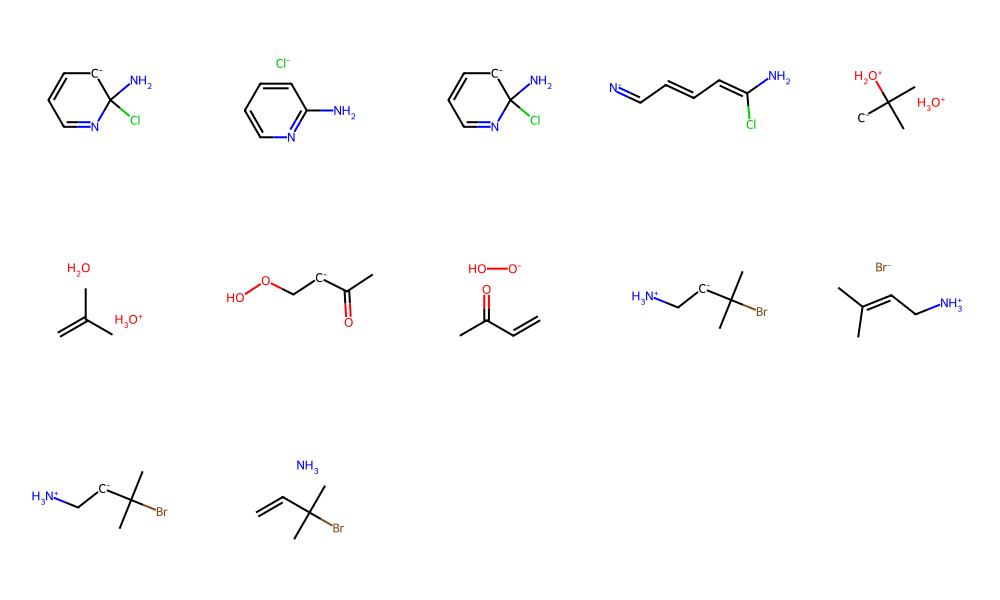

In [44]:
from rdkit.Chem import Draw

# Select a specific cluster to visualize (e.g., cluster_id)
cluster_members = clusters[3]

# For each member index, find the corresponding training directory

mols = []
legends = []
# subdirs is sorted list of training subdirectory names (as strings)
# cluster_members contains indices into the mask-filtered X (i.e., indices of probable outcomes)
# We need to map these indices back to the original subdirs

# First, get the indices of all probable outcomes in the original bitvectors list
probable_indices = np.where(mask)[0]

for idx in cluster_members:
    # Use bitvector_origins.txt to map idx to folder and choice id
    with open("bitvector_origins.txt", "r") as origin_file:
        for line in origin_file:
            parts = line.strip().split(",")
            if int(parts[0]) == probable_indices[idx]:
                folder_path = parts[1]
                subdir = os.path.basename(folder_path)
                mol_id = parts[2]
                break
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    mol_path = os.path.join(folder_path,  "mol_" + str(mol_id) + '.pkl')
    json_path = os.path.join(folder_path, 'data.json')
    # Load molecule
    with open(pkl_path, "rb") as f:
        mol = pickle.load(f)
        mols.append(mol)
    # Load probable mechanism info
    with open(mol_path, 'rb') as f:
        mol = pickle.load(f)
        mols.append(mol)
    legends.append(f"ID {subdir}")

# Visualize molecules with legends
Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200, 200))

In [76]:
clf = joblib.load('models/v12/xg_model.pkl')

In [77]:
beckmann = Chem.MolFromSmiles('[OH2+]N=C1CCCCC1')
alkyl = Chem.MolFromSmiles('CC(C)(C)[CH2+]')
tert_brom = Chem.MolFromSmiles('CC1(Br)CCCCC1')
bv = Chem.MolFromSmiles('OOC1(O)CCCCC1')
bv_p = Chem.MolFromSmiles('[OH2+]OC1(O)CCCCC1')
r_aldol = Chem.MolFromSmiles('COC(C)([O-])C(C)(C)C(C)=O')
ohira_bestman = Chem.MolFromSmiles('CC(=[C])C1=CC=CC=C1')
diazo = Chem.MolFromSmiles('N#[N+]C1=CC=CC=C1')
brook = Chem.MolFromSmiles('CC(C[O-])[Si](C)(C)C')
benzoin = Chem.MolFromSmiles('N#CC([O-])(c1ccccc1)C(O)c1ccccc1')

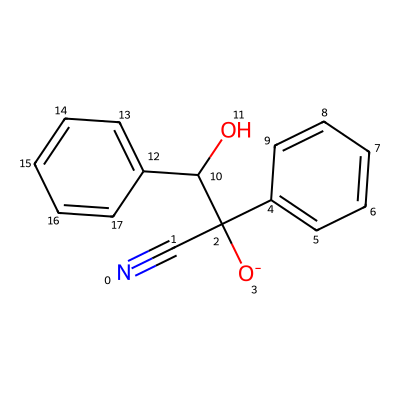

In [80]:
benzoin

In [79]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [23]:
def make_fingerprint(sm, mech):
    mech_type = [0] * 11
    mech_type[mech[0]] = 1
    atom_fps = []
    for i in range(1, 5):
        if mech[i] is None:
            atom_fps.append(make_atom_fingerprint(None))
        else:
            atom_fps.append(make_atom_fingerprint(sm.GetAtomWithIdx(mech[i])))
    if mech[3]:
        b1 = make_bond_fingerprint(sm.GetBondBetweenAtoms(mech[1], mech[3]))
    else:
        b1 = [0] * 4
    if mech[4]:
        b2 = make_bond_fingerprint(sm.GetBondBetweenAtoms(mech[2], mech[4]))
    else:
        b2 = [0] * 4
    r = new_bond_fingerprint(sm, mech[1], mech[2])
    sum_finger_print = mech_type + atom_fps[0] + atom_fps[1] + atom_fps[2] + atom_fps[3] + b1 + b2 + r
    return sum_finger_print

In [84]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')
#clf = joblib.load('models/v12/xg_model.pkl')
mol = benzoin
arrow = [1, 3, 2, None, 1]
sum_finger_print = make_fingerprint(mol, arrow)

In [85]:
print(clf.predict(np.array([sum_finger_print]).reshape(1, -1)))

ValueError: Feature shape mismatch, expected: 160, got 168

In [35]:
clf

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [196]:
outcomes.count(1)

214

In [197]:
len(outcomes)

1506

In [199]:
(1506-214)/214

6.037383177570093

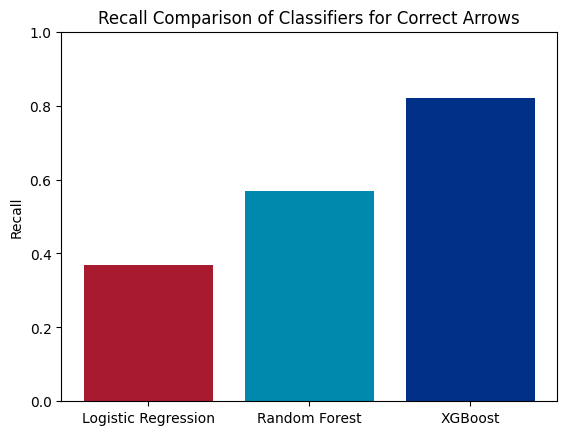

In [44]:
recalls = [0.37, 0.57, 0.82]
labels = ["Logistic Regression", "Random Forest", "XGBoost"]
plt.bar(labels, recalls, color=custom_c[:len(labels)])
plt.ylabel("Recall")
plt.title("Recall Comparison of Classifiers for Correct Arrows")
plt.ylim(0, 1)
plt.show()

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

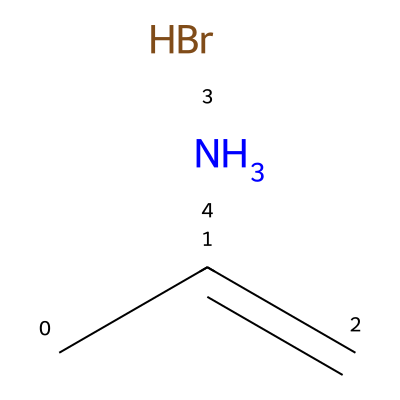

In [34]:
with open("training/20250611/144/mol_0.pkl", "rb") as f:
    debug_mol = pickle.load(f)
debug_mol